# Extract BloodMNIST Dataset

In [1]:
import os
import zipfile
import time
import glob


# ==========================================
# TODO: UPDATE THIS PATH TO YOUR ZIP FILE
# ==========================================
ZIP_PATH = '/content/drive/MyDrive/Intro to CV/BloodMNIST.zip'
EXTRACT_DIR = '/content/BloodMNIST'

if not os.path.exists(EXTRACT_DIR):
    print(f"Extracting {ZIP_PATH} to local Colab disk for fast I/O...")
    start_t = time.time()
    with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(EXTRACT_DIR)
    print(f"Extraction completed in {time.time() - start_t:.2f}s")
else:
    print("Dataset already extracted.")

# Automatically locate the folder containing 'train', 'val', and 'test'
DATASET_ROOT = None
for root, dirs, files in os.walk(EXTRACT_DIR):
    if {'train', 'val', 'test'}.issubset(set(dirs)):
        DATASET_ROOT = root
        break

if DATASET_ROOT is None:
    raise FileNotFoundError("Could not find 'train', 'val', 'test' folders inside the extracted zip. Check structure!")

print(f"Dataset Root successfully located at: {DATASET_ROOT}")
classes = sorted(os.listdir(os.path.join(DATASET_ROOT, 'train')))
print(f"Detected {len(classes)} classes: {classes}")

Extracting /content/drive/MyDrive/Intro to CV/BloodMNIST.zip to local Colab disk for fast I/O...
Extraction completed in 21.79s
Dataset Root successfully located at: /content/BloodMNIST
Detected 8 classes: ['basophil', 'eosinophil', 'erythroblast', 'immature_granulocytes(myelocytes,_metamyelocytes_and_promyelocytes)', 'lymphocyte', 'monocyte', 'neutrophil', 'platelet']


# Imports, Fixed Seeds & Configuration

In [2]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from joblib import Parallel, delayed
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, cohen_kappa_score, matthews_corrcoef,
    confusion_matrix
)

# Set Fixed Random Seeds for Reproducibility (Table 1 Requirement)
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Executing pipeline on device: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

# Table 1 Parameters
IMG_SIZE = (128, 128)
ORIENTATIONS = 9
PIXELS_PER_CELL = (8, 8)
CELLS_PER_BLOCK = (2, 2)
BLOCK_NORM = 'L2-Hys'

Executing pipeline on device: cpu (CPU)


# Fast Parallel Preprocessing & HOG Feature Extraction

In [3]:
def create_opencv_hog():
    winSize = IMG_SIZE
    blockSize = (PIXELS_PER_CELL[0] * CELLS_PER_BLOCK[0], PIXELS_PER_CELL[1] * CELLS_PER_BLOCK[1]) # (16, 16)
    blockStride = PIXELS_PER_CELL # (8, 8)
    cellSize = PIXELS_PER_CELL    # (8, 8)
    nbins = ORIENTATIONS          # 9
    # L2Hys normalization with 0.2 threshold matches Table 1 specification
    return cv2.HOGDescriptor(winSize, blockSize, blockStride, cellSize, nbins, 1, -1, 0, 0.2, False, 64, True)

def process_single_image(img_path, label):
    # Read image, convert to grayscale, resize to 128x128
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        return None, None
    img_resized = cv2.resize(img, IMG_SIZE, interpolation=cv2.INTER_AREA)
    hog = create_opencv_hog()
    feat = hog.compute(img_resized).flatten().astype(np.float32)
    return feat, label

def load_split_hog(split_name, class_list, max_samples_per_class=None):
    split_dir = os.path.join(DATASET_ROOT, split_name)
    tasks = []
    for idx, cls_name in enumerate(class_list):
        cls_dir = os.path.join(split_dir, cls_name)
        img_Files = sorted(glob.glob(os.path.join(cls_dir, '*.*')))
        if max_samples_per_class is not None and len(img_Files) > max_samples_per_class:
            # Stratified fixed subsample if requested
            rng = np.random.RandomState(SEED + idx)
            chosen = rng.choice(img_Files, max_samples_per_class, replace=False)
            img_Files = sorted(list(chosen))
        for f in img_Files:
            tasks.append((f, idx))

    print(f"Extracting HOG features for '{split_name}' split ({len(tasks)} images)...")
    t0 = time.time()
    results = Parallel(n_jobs=-1, prefer="threads")(
        delayed(process_single_image)(f, lbl) for f, lbl in tasks
    )
    X = np.array([r[0] for r in results if r[0] is not None], dtype=np.float32)
    y = np.array([r[1] for r in results if r[0] is not None], dtype=np.int64)
    elapsed = time.time() - t0
    print(f" -> Done in {elapsed:.2f}s | Shape: {X.shape}")
    return X, y, elapsed

# Extract all splits (Using full dataset; set max_samples_per_class=None for full 17.1k images)
X_train_raw, y_train, t_hog_train = load_split_hog('train', classes)
X_val_raw, y_val, t_hog_val       = load_split_hog('val', classes)
X_test_raw, y_test, t_hog_test    = load_split_hog('test', classes)

# Standardize features (fit ONLY on training split to prevent data leakage)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_val   = scaler.transform(X_val_raw)
X_test  = scaler.transform(X_test_raw)

TOTAL_FEATURES = X_train.shape[1]
print(f"\nTotal Extracted HOG Features per image: {TOTAL_FEATURES}")

Extracting HOG features for 'train' split (11959 images)...
 -> Done in 31.99s | Shape: (11959, 8100)
Extracting HOG features for 'val' split (1712 images)...
 -> Done in 3.95s | Shape: (1712, 8100)
Extracting HOG features for 'test' split (3421 images)...
 -> Done in 10.09s | Shape: (3421, 8100)

Total Extracted HOG Features per image: 8100


# Evaluation Metrics & Multiclass Specificity Helper

In [4]:
def compute_macro_specificity(y_true, y_pred, num_classes):
    cm = confusion_matrix(y_true, y_pred, labels=range(num_classes))
    specificities = []
    total_samples = np.sum(cm)
    for i in range(num_classes):
        tp = cm[i, i]
        fp = np.sum(cm[:, i]) - tp
        fn = np.sum(cm[i, :]) - tp
        tn = total_samples - (tp + fp + fn)
        spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
        specificities.append(spec)
    return np.mean(specificities)

def evaluate_predictions(y_true, y_pred, num_classes=len(classes)):
    return {
        "Accuracy (%)": accuracy_score(y_true, y_pred) * 100,
        "Precision (Macro, %)": precision_score(y_true, y_pred, average='macro', zero_division=0) * 100,
        "Recall (Macro, %)": recall_score(y_true, y_pred, average='macro', zero_division=0) * 100,
        "Macro-F1 (%)": f1_score(y_true, y_pred, average='macro', zero_division=0) * 100,
        "Weighted-F1 (%)": f1_score(y_true, y_pred, average='weighted', zero_division=0) * 100,
        "Balanced accuracy (%)": balanced_accuracy_score(y_true, y_pred) * 100,
        "Specificity (Macro, %)": compute_macro_specificity(y_true, y_pred, num_classes) * 100,
        "Cohen's kappa": cohen_kappa_score(y_true, y_pred),
        "Matthews correlation coefficient": matthews_corrcoef(y_true, y_pred)
    }

# GPU-Accelerated RBF-SVM Evaluator & Baseline Pipeline

In [6]:
MAX_GA_TRAIN = 3500
MAX_GA_VAL   = 1200

def get_stratified_indices(y, max_total, seed=SEED):
    rng = np.random.RandomState(seed)
    unique_classes, counts = np.unique(y, return_counts=True)
    props = counts / len(y)
    indices = []
    for c, p in zip(unique_classes, props):
        c_idx = np.where(y == c)[0]
        n_pick = min(len(c_idx), max(1, int(round(p * max_total))))
        indices.extend(rng.choice(c_idx, n_pick, replace=False))
    return np.array( sorted(indices) )

ga_train_idx = get_stratified_indices(y_train, MAX_GA_TRAIN)
ga_val_idx   = get_stratified_indices(y_val, MAX_GA_VAL)

X_tr_gpu = torch.tensor(X_train[ga_train_idx], device=device, dtype=torch.float32)
y_tr_gpu = torch.tensor(y_train[ga_train_idx], device=device, dtype=torch.long)
Y_tr_onehot = torch.nn.functional.one_hot(y_tr_gpu, num_classes=len(classes)).float()

X_va_gpu = torch.tensor(X_val[ga_val_idx], device=device, dtype=torch.float32)
y_va_cpu = y_val[ga_val_idx]

def gpu_rbf_svm_predict_val(feature_mask, C_val=5.0):
    """
    Evaluates an RBF-kernel L2-SVM on the GPU using the selected binary feature mask.
    """
    idx = torch.where(torch.tensor(feature_mask, device=device, dtype=torch.bool))[0]
    if len(idx) == 0:
        return np.zeros_like(y_va_cpu)

    X_tr_sub = X_tr_gpu[:, idx]
    X_va_sub = X_va_gpu[:, idx]

    # Match sklearn's gamma='scale' formulation: 1 / (n_features * X.var())
    gamma = 1.0 / (len(idx) * 1.0)

    # Compute RBF Gram Matrix on GPU
    dist_tr = torch.cdist(X_tr_sub, X_tr_sub, p=2.0).pow(2)
    K_tr = torch.exp(-gamma * dist_tr)

    # Solve dual weights (K + (1/C)*I) * Alpha = Y
    reg = torch.eye(K_tr.shape[0], device=device) * (1.0 / C_val)
    Alpha = torch.linalg.solve(K_tr + reg, Y_tr_onehot)

    # Predict on Validation
    dist_va = torch.cdist(X_va_sub, X_tr_sub, p=2.0).pow(2)
    K_va = torch.exp(-gamma * dist_va)
    scores = K_va @ Alpha
    preds = torch.argmax(scores, dim=1).cpu().numpy()
    return preds

# 1. Tune C on Validation Set for Baseline (Table 1 requirement)
print("Tuning Baseline RBF-SVM Hyperparameter C on Validation Set...")
best_C = 1.0
best_val_f1 = -1.0
all_features_mask = np.ones(TOTAL_FEATURES, dtype=bool)

for c_candidate in [0.5, 1.0, 5.0, 10.0]:
    val_preds = gpu_rbf_svm_predict_val(all_features_mask, C_val=c_candidate)
    score = f1_score(y_va_cpu, val_preds, average='macro')
    print(f" -> Validation Macro-F1 (C={c_candidate}): {score*100:.2f}%")
    if score > best_val_f1:
        best_val_f1 = score
        best_C = c_candidate

print(f"\nSelected Optimal C = {best_C} (Validation Macro-F1: {best_val_f1*100:.2f}%)")

# 2. Train Full Baseline HOG + SVM (sklearn SVC with RBF kernel) on Training Set
print("\nTraining Baseline HOG + SVM (Full 8,100 features) on Training Set...")
t0_base = time.time()
baseline_svm = SVC(kernel='rbf', C=best_C, gamma='scale', random_state=SEED)
baseline_svm.fit(X_train, y_train)
baseline_train_time = time.time() - t0_base

t0_base_inf = time.time()
y_test_pred_base = baseline_svm.predict(X_test)
baseline_test_time = time.time() - t0_base_inf

baseline_metrics = evaluate_predictions(y_test, y_test_pred_base)
print(f"Baseline Training Time: {baseline_train_time:.2f}s | Inference Time: {baseline_test_time:.2f}s")
print(f"Baseline Test Accuracy: {baseline_metrics['Accuracy (%)']:.2f}% | Test Macro-F1: {baseline_metrics['Macro-F1 (%)']:.2f}%")

Tuning Baseline RBF-SVM Hyperparameter C on Validation Set...
 -> Validation Macro-F1 (C=0.5): 68.95%
 -> Validation Macro-F1 (C=1.0): 72.32%
 -> Validation Macro-F1 (C=5.0): 74.34%
 -> Validation Macro-F1 (C=10.0): 74.68%

Selected Optimal C = 10.0 (Validation Macro-F1: 74.68%)

Training Baseline HOG + SVM (Full 8,100 features) on Training Set...
Baseline Training Time: 994.17s | Inference Time: 349.45s
Baseline Test Accuracy: 82.81% | Test Macro-F1: 82.15%


# Genetic Algorithm Implementation & Two-Setting Experiment

In [7]:
class GeneticFeatureSelector:
    def __init__(self, n_features, pop_size=24, generations=20, mutation_prob=0.02,
                 crossover_prob=0.85, penalty_alpha=0.04, C_val=5.0, seed=SEED):
        self.n_features = n_features
        self.pop_size = pop_size
        self.generations = generations
        self.mutation_prob = mutation_prob
        self.crossover_prob = crossover_prob
        self.penalty_alpha = penalty_alpha
        self.C_val = C_val
        self.rng = np.random.RandomState(seed)

    def initialize_population(self):
        # Initialize chromosomes with varied feature inclusion probabilities (15% to 50%)
        # to encourage both dimensionality reduction and high accuracy
        pop = np.zeros((self.pop_size, self.n_features), dtype=bool)
        for i in range(self.pop_size):
            p_keep = self.rng.uniform(0.15, 0.55)
            pop[i] = self.rng.rand(self.n_features) < p_keep
            if not np.any(pop[i]):
                pop[i, self.rng.randint(0, self.n_features)] = True
        return pop

    def evaluate_fitness(self, chromosome):
        n_selected = np.sum(chromosome)
        if n_selected == 0:
            return 0.0, 0.0
        preds = gpu_rbf_svm_predict_val(chromosome, C_val=self.C_val)
        macro_f1 = f1_score(y_va_cpu, preds, average='macro', zero_division=0)
        # Fitness = Validation Macro-F1 - Penalty * (Selected_Features / Total_Features)
        feature_ratio = n_selected / self.n_features
        fitness = macro_f1 - (self.penalty_alpha * feature_ratio)
        return fitness, macro_f1

    def tournament_selection(self, pop, fitnesses, k=3):
        selected = np.zeros_like(pop)
        for i in range(self.pop_size):
            candidates = self.rng.choice(self.pop_size, k, replace=False)
            best_idx = candidates[np.argmax(fitnesses[candidates])]
            selected[i] = pop[best_idx].copy()
        return selected

    def crossover(self, parent1, parent2):
        if self.rng.rand() < self.crossover_prob:
            # Two-point crossover for spatial HOG block preservation
            pt1, pt2 = sorted(self.rng.choice(self.n_features, 2, replace=False))
            child1 = parent1.copy()
            child2 = parent2.copy()
            child1[pt1:pt2] = parent2[pt1:pt2]
            child2[pt1:pt2] = parent1[pt1:pt2]
            return child1, child2
        return parent1.copy(), parent2.copy()

    def mutate(self, chromosome):
        flip_mask = self.rng.rand(self.n_features) < self.mutation_prob
        mutated = np.logical_xor(chromosome, flip_mask)
        if not np.any(mutated):
            mutated[self.rng.randint(0, self.n_features)] = True
        return mutated

    def run(self, setting_name="GA Setting"):
        print(f"\n--- Running {setting_name} (Pop={self.pop_size}, Gen={self.generations}, Mut={self.mutation_prob}) ---")
        t0 = time.time()
        pop = self.initialize_population()

        best_chromosome = None
        best_fitness = -np.inf
        best_val_f1 = -np.inf

        history = {
            'gen': [], 'best_fitness': [], 'mean_fitness': [],
            'best_val_f1': [], 'selected_features': []
        }

        for gen in range(1, self.generations + 1):
            fitnesses = np.zeros(self.pop_size)
            f1_scores = np.zeros(self.pop_size)

            for i in range(self.pop_size):
                fit, f1 = self.evaluate_fitness(pop[i])
                fitnesses[i] = fit
                f1_scores[i] = f1

                if fit > best_fitness:
                    best_fitness = fit
                    best_val_f1 = f1
                    best_chromosome = pop[i].copy()

            history['gen'].append(gen)
            history['best_fitness'].append(best_fitness)
            history['mean_fitness'].append(np.mean(fitnesses))
            history['best_val_f1'].append(best_val_f1 * 100)
            history['selected_features'].append(int(np.sum(best_chromosome)))

            if gen == 1 or gen % 5 == 0 or gen == self.generations:
                print(f"Gen {gen:02d}/{self.generations:02d} | Best Fitness: {best_fitness:.4f} | "
                      f"Val Macro-F1: {best_val_f1*100:.2f}% | Selected Features: {np.sum(best_chromosome)}/{self.n_features}")

            # Elitism: preserve top 2 individuals
            elite_indices = np.argsort(fitnesses)[-2:]
            elites = pop[elite_indices].copy()

            # Selection, Crossover, Mutation
            selected_pop = self.tournament_selection(pop, fitnesses)
            next_pop = []
            for i in range(0, self.pop_size - 2, 2):
                p1, p2 = selected_pop[i], selected_pop[i+1]
                c1, c2 = self.crossover(p1, p2)
                next_pop.append(self.mutate(c1))
                next_pop.append(self.mutate(c2))

            next_pop.extend(elites)
            pop = np.array(next_pop[:self.pop_size], dtype=bool)

        elapsed = time.time() - t0
        print(f"Completed {setting_name} in {elapsed:.2f}s | Final Features: {np.sum(best_chromosome)} ({np.sum(best_chromosome)/self.n_features*100:.1f}%)")
        return best_chromosome, history, elapsed

# Experiment with TWO distinct GA Settings (Experimental Requirement 3)
ga_setting_1 = GeneticFeatureSelector(
    n_features=TOTAL_FEATURES, pop_size=20, generations=20,
    mutation_prob=0.01, penalty_alpha=0.035, C_val=best_C, seed=SEED
)
mask_s1, hist_s1, time_s1 = ga_setting_1.run("GA Setting 1 (Pop=20, Mut=0.01)")

ga_setting_2 = GeneticFeatureSelector(
    n_features=TOTAL_FEATURES, pop_size=30, generations=20,
    mutation_prob=0.025, penalty_alpha=0.035, C_val=best_C, seed=SEED + 7
)
mask_s2, hist_s2, time_s2 = ga_setting_2.run("GA Setting 2 (Pop=30, Mut=0.025)")


--- Running GA Setting 1 (Pop=20, Mut=0.01) (Pop=20, Gen=20, Mut=0.01) ---
Gen 01/20 | Best Fitness: 0.7328 | Val Macro-F1: 74.67% | Selected Features: 3217/8100
Gen 05/20 | Best Fitness: 0.7437 | Val Macro-F1: 75.77% | Selected Features: 3251/8100
Gen 10/20 | Best Fitness: 0.7477 | Val Macro-F1: 76.18% | Selected Features: 3268/8100
Gen 15/20 | Best Fitness: 0.7534 | Val Macro-F1: 76.82% | Selected Features: 3420/8100
Gen 20/20 | Best Fitness: 0.7588 | Val Macro-F1: 77.38% | Selected Features: 3468/8100
Completed GA Setting 1 (Pop=20, Mut=0.01) in 1229.26s | Final Features: 3468 (42.8%)

--- Running GA Setting 2 (Pop=30, Mut=0.025) (Pop=30, Gen=20, Mut=0.025) ---
Gen 01/20 | Best Fitness: 0.7428 | Val Macro-F1: 75.16% | Selected Features: 2025/8100
Gen 05/20 | Best Fitness: 0.7536 | Val Macro-F1: 76.36% | Selected Features: 2313/8100
Gen 10/20 | Best Fitness: 0.7573 | Val Macro-F1: 76.87% | Selected Features: 2642/8100
Gen 15/20 | Best Fitness: 0.7574 | Val Macro-F1: 76.98% | Selecte

# Final Model Selection & Test Set Evaluation

In [8]:
# Choose the winning GA setting based on validation fitness BEFORE touching the test set
if hist_s2['best_fitness'][-1] >= hist_s1['best_fitness'][-1]:
    winning_setting_name = "GA Setting 2 (Pop=30, Mut=0.025)"
    best_ga_mask = mask_s2
    best_ga_hist = hist_s2
    ga_search_time = time_s2
else:
    winning_setting_name = "GA Setting 1 (Pop=20, Mut=0.01)"
    best_ga_mask = mask_s1
    best_ga_hist = hist_s1
    ga_search_time = time_s1

selected_indices = np.where(best_ga_mask)[0]
num_selected = len(selected_indices)
reduction_pct = (1.0 - (num_selected / TOTAL_FEATURES)) * 100

print(f"Winning Configuration on Validation Set: {winning_setting_name}")
print(f"Selected {num_selected} / {TOTAL_FEATURES} features ({reduction_pct:.2f}% dimensionality reduction)")

# Train Final Proposed GA-HOG + SVM on Full Training Split
print("\nTraining Final GA-HOG + SVM on Full Training Set...")
t0_ga_svm = time.time()
proposed_svm = SVC(kernel='rbf', C=best_C, gamma='scale', random_state=SEED)
proposed_svm.fit(X_train[:, selected_indices], y_train)
ga_svm_train_time = time.time() - t0_ga_svm

t0_ga_inf = time.time()
y_test_pred_ga = proposed_svm.predict(X_test[:, selected_indices])
ga_svm_test_time = time.time() - t0_ga_inf

proposed_metrics = evaluate_predictions(y_test, y_test_pred_ga)

# Build Table 2 DataFrame
table2_rows = []
for metric_name in baseline_metrics.keys():
    b_val = baseline_metrics[metric_name]
    p_val = proposed_metrics[metric_name]
    diff = p_val - b_val
    sign = "+" if diff >= 0 else ""
    if "%" in metric_name:
        table2_rows.append({
            "Metric": metric_name,
            "HOG + SVM (Baseline)": f"{b_val:.2f}%",
            "GA-HOG + SVM (Proposed)": f"{p_val:.2f}%",
            "Improvement": f"{sign}{diff:.2f}%"
        })
    else:
        table2_rows.append({
            "Metric": metric_name,
            "HOG + SVM (Baseline)": f"{b_val:.4f}",
            "GA-HOG + SVM (Proposed)": f"{p_val:.4f}",
            "Improvement": f"{sign}{diff:.4f}"
        })

df_table2 = pd.DataFrame(table2_rows)
print("\n" + "="*80)
print("TABLE 2: MAIN PERFORMANCE COMPARISON (TEST SET)")
print("="*80)
print(df_table2.to_string(index=False))

# Additional Summary Table for GA Settings & Computational Cost
df_comp = pd.DataFrame([
    {
        "Method": "Baseline: HOG + SVM",
        "Features Used": TOTAL_FEATURES,
        "Dimensionality Reduction": "0.00%",
        "GA Search Time (s)": 0.0,
        "SVM Train Time (s)": round(baseline_train_time, 2),
        "Test Inference Time (s)": round(baseline_test_time, 2),
        "Val Macro-F1 (%)": round(best_val_f1 * 100, 2),
        "Test Macro-F1 (%)": round(baseline_metrics["Macro-F1 (%)"], 2)
    },
    {
        "Method": "GA Setting 1 (Pop=20, Mut=0.01)",
        "Features Used": int(np.sum(mask_s1)),
        "Dimensionality Reduction": f"{(1 - np.sum(mask_s1)/TOTAL_FEATURES)*100:.2f}%",
        "GA Search Time (s)": round(time_s1, 2),
        "SVM Train Time (s)": "-",
        "Test Inference Time (s)": "-",
        "Val Macro-F1 (%)": round(hist_s1['best_val_f1'][-1], 2),
        "Test Macro-F1 (%)": "Selected if Best Val"
    },
    {
        "Method": "GA Setting 2 (Pop=30, Mut=0.025)",
        "Features Used": int(np.sum(mask_s2)),
        "Dimensionality Reduction": f"{(1 - np.sum(mask_s2)/TOTAL_FEATURES)*100:.2f}%",
        "GA Search Time (s)": round(time_s2, 2),
        "SVM Train Time (s)": "-",
        "Test Inference Time (s)": "-",
        "Val Macro-F1 (%)": round(hist_s2['best_val_f1'][-1], 2),
        "Test Macro-F1 (%)": "Selected if Best Val"
    },
    {
        "Method": f"Final Proposed: {winning_setting_name}",
        "Features Used": num_selected,
        "Dimensionality Reduction": f"{reduction_pct:.2f}%",
        "GA Search Time (s)": round(ga_search_time, 2),
        "SVM Train Time (s)": round(ga_svm_train_time, 2),
        "Test Inference Time (s)": round(ga_svm_test_time, 2),
        "Val Macro-F1 (%)": round(best_ga_hist['best_val_f1'][-1], 2),
        "Test Macro-F1 (%)": round(proposed_metrics["Macro-F1 (%)"], 2)
    }
])
print("\n" + "="*80)
print("COMPUTATIONAL COST & GA SETTINGS SUMMARY")
print("="*80)
print(df_comp.to_string(index=False))

Winning Configuration on Validation Set: GA Setting 2 (Pop=30, Mut=0.025)
Selected 3113 / 8100 features (61.57% dimensionality reduction)

Training Final GA-HOG + SVM on Full Training Set...

TABLE 2: MAIN PERFORMANCE COMPARISON (TEST SET)
                          Metric HOG + SVM (Baseline) GA-HOG + SVM (Proposed) Improvement
                    Accuracy (%)               82.81%                  81.58%      -1.23%
            Precision (Macro, %)               84.04%                  82.78%      -1.26%
               Recall (Macro, %)               80.97%                  79.92%      -1.05%
                    Macro-F1 (%)               82.15%                  81.03%      -1.12%
                 Weighted-F1 (%)               82.73%                  81.54%      -1.19%
           Balanced accuracy (%)               80.97%                  79.92%      -1.05%
          Specificity (Macro, %)               97.45%                  97.28%      -0.18%
                   Cohen's kappa        

# Generate & Save All Required Plots

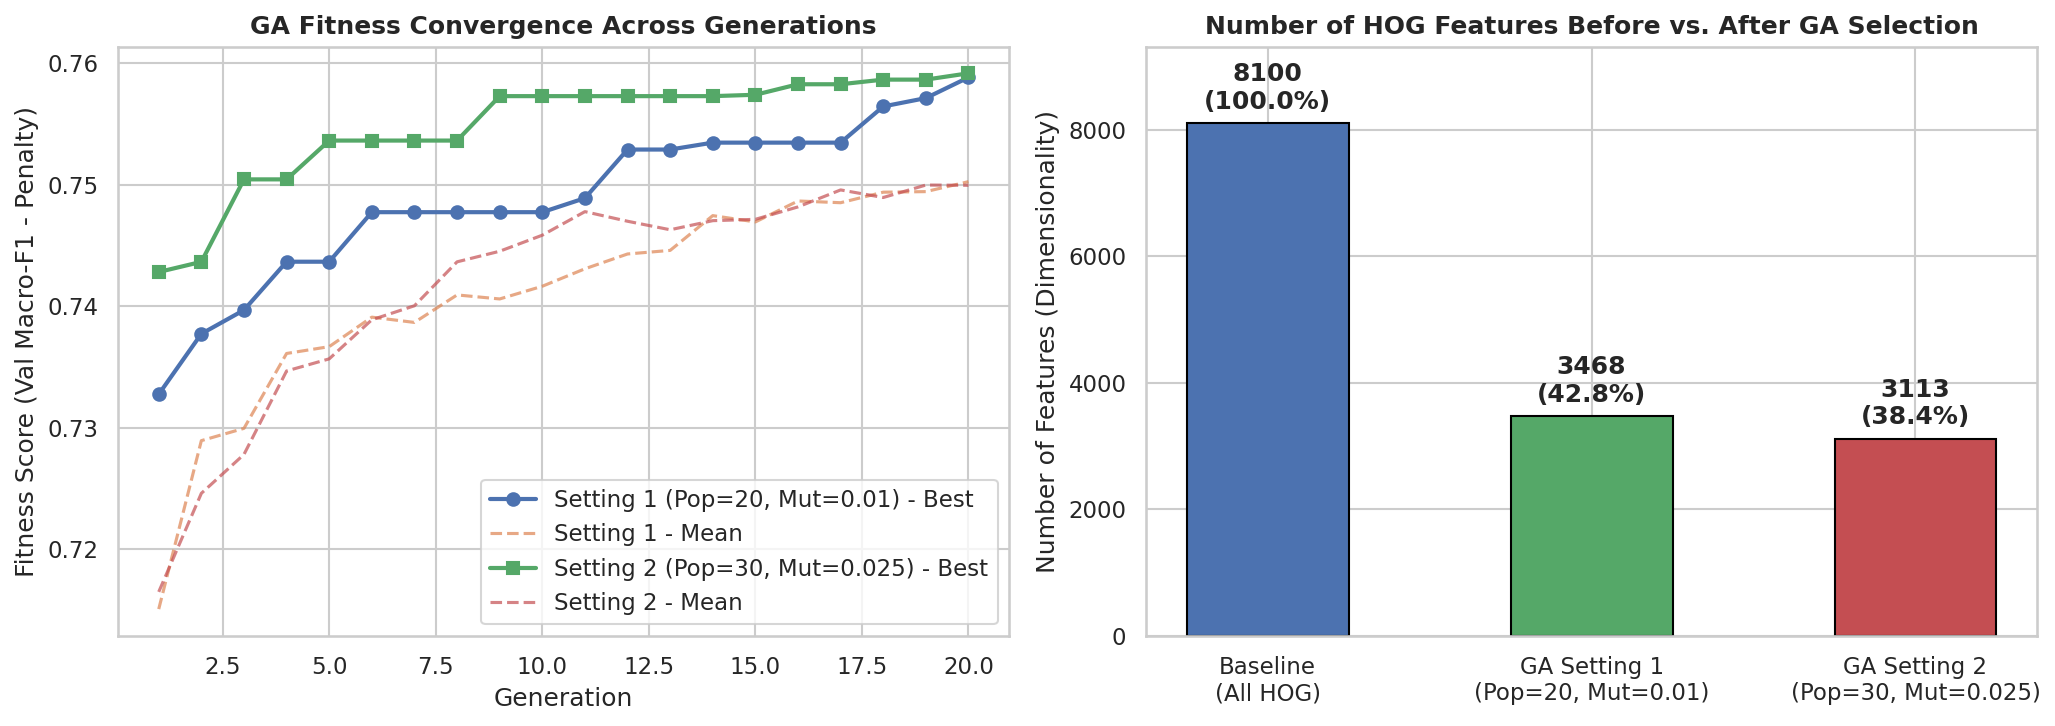

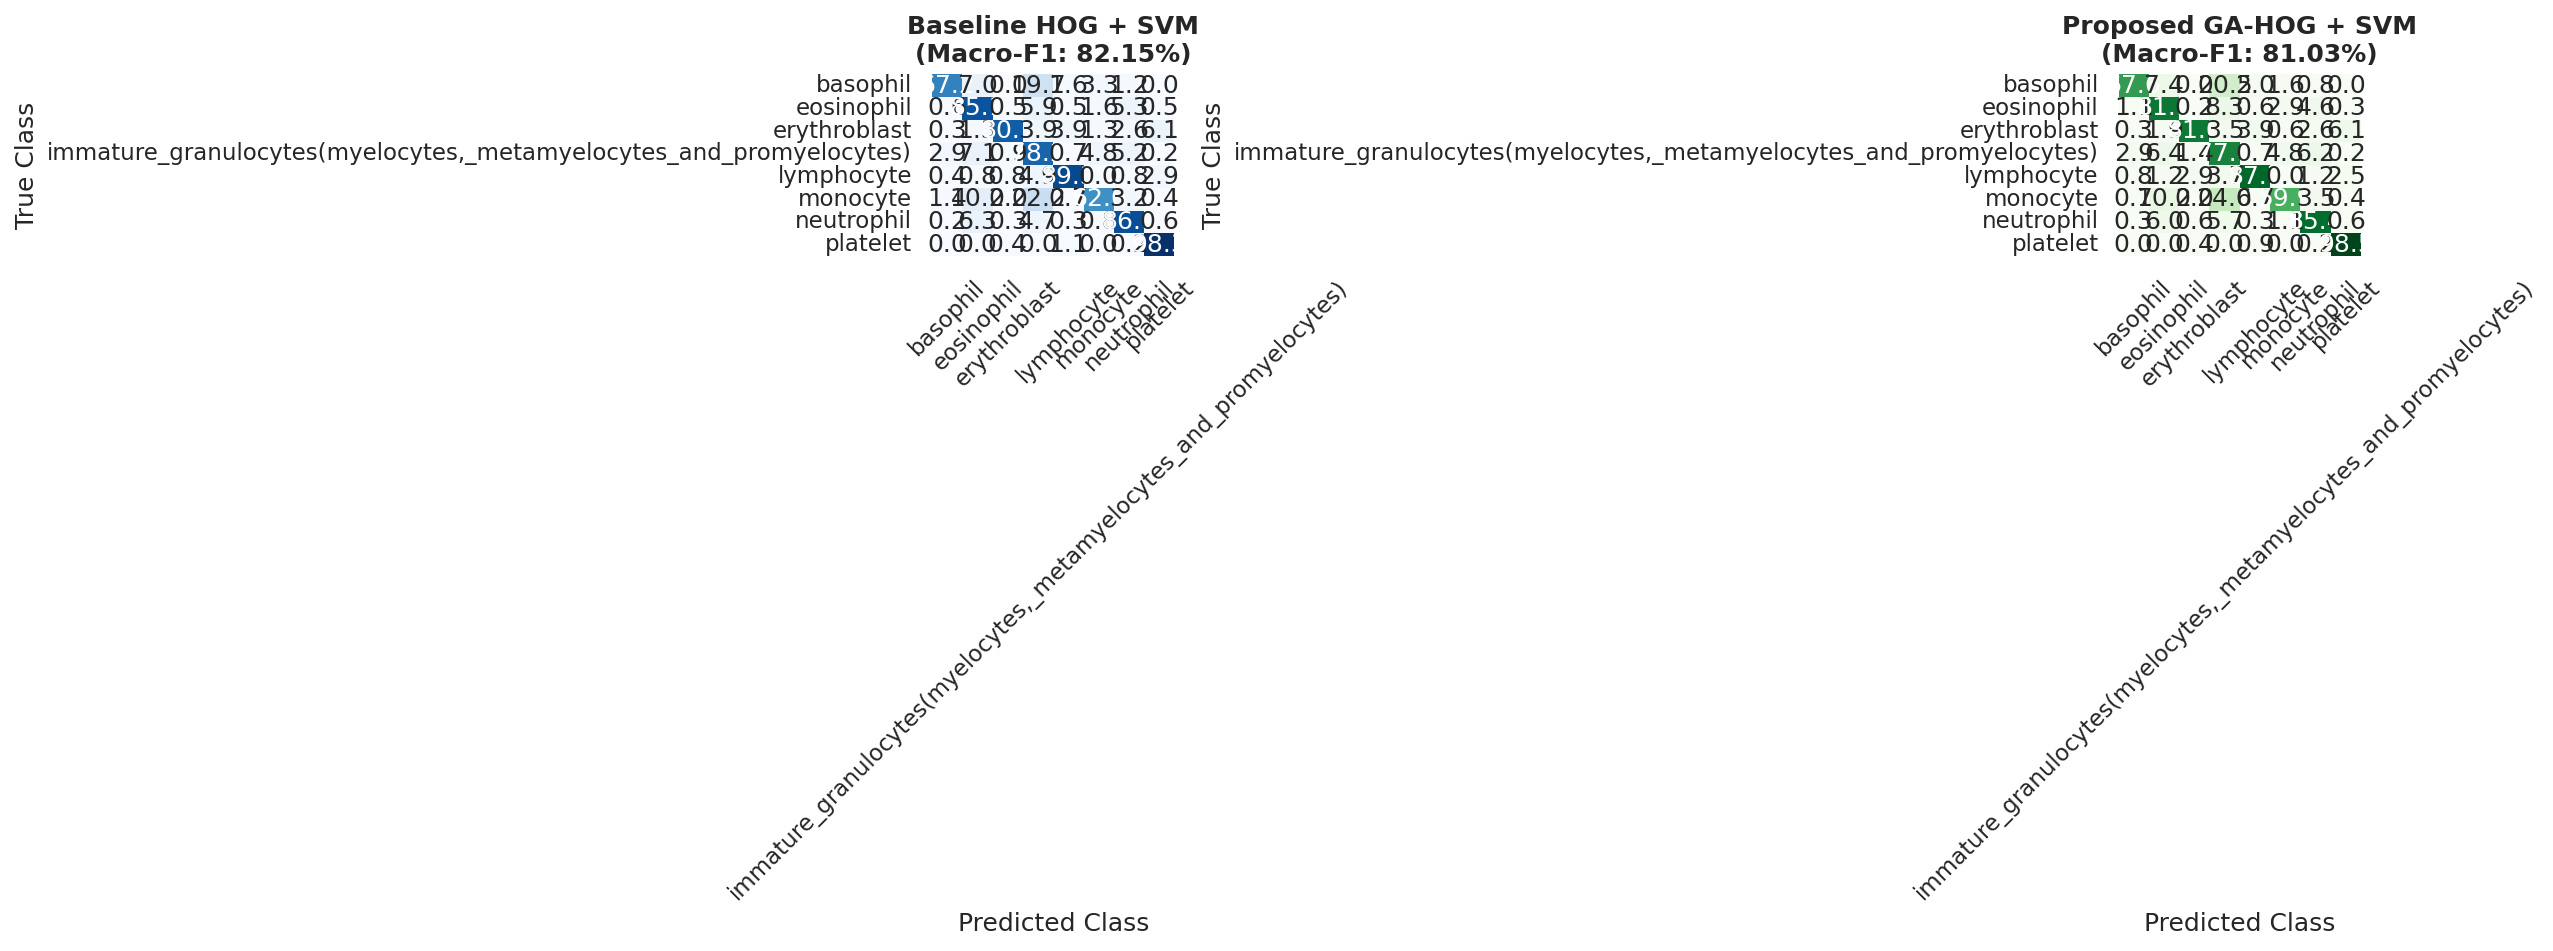

In [9]:
plt.rcParams['figure.dpi'] = 150
sns.set_theme(style="whitegrid")

# 1. Plot GA Fitness & Validation Macro-F1 Across Generations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(hist_s1['gen'], hist_s1['best_fitness'], marker='o', linewidth=2, label='Setting 1 (Pop=20, Mut=0.01) - Best')
axes[0].plot(hist_s1['gen'], hist_s1['mean_fitness'], linestyle='--', alpha=0.7, label='Setting 1 - Mean')
axes[0].plot(hist_s2['gen'], hist_s2['best_fitness'], marker='s', linewidth=2, label='Setting 2 (Pop=30, Mut=0.025) - Best')
axes[0].plot(hist_s2['gen'], hist_s2['mean_fitness'], linestyle='--', alpha=0.7, label='Setting 2 - Mean')
axes[0].set_title('GA Fitness Convergence Across Generations', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Generation')
axes[0].set_ylabel('Fitness Score (Val Macro-F1 - Penalty)')
axes[0].legend()

# 2. Plot Number of Features & Training Time Before vs After Selection
methods_feat = ['Baseline\n(All HOG)', 'GA Setting 1\n(Pop=20, Mut=0.01)', 'GA Setting 2\n(Pop=30, Mut=0.025)']
counts_feat = [TOTAL_FEATURES, int(np.sum(mask_s1)), int(np.sum(mask_s2))]
colors = ['#4C72B0', '#55A868', '#C44E52']

bars = axes[1].bar(methods_feat, counts_feat, color=colors, width=0.5, edgecolor='black')
axes[1].set_title('Number of HOG Features Before vs. After GA Selection', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Number of Features (Dimensionality)')
axes[1].set_ylim(0, TOTAL_FEATURES * 1.15)
for bar in bars:
    h = bar.get_height()
    pct = (h / TOTAL_FEATURES) * 100
    axes[1].text(bar.get_x() + bar.get_width()/2., h + 150, f"{h}\n({pct:.1f}%)", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig('ga_fitness_and_features.png', bbox_inches='tight')
plt.show()

# 3. Confusion Matrix Comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
cm_base = confusion_matrix(y_test, y_test_pred_base, normalize='true') * 100
cm_ga   = confusion_matrix(y_test, y_test_pred_ga, normalize='true') * 100

sns.heatmap(cm_base, annot=True, fmt='.1f', cmap='Blues', xticklabels=classes, yticklabels=classes, ax=axes[0], cbar=False)
axes[0].set_title(f"Baseline HOG + SVM\n(Macro-F1: {baseline_metrics['Macro-F1 (%)']:.2f}%)", fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted Class')
axes[0].set_ylabel('True Class')
axes[0].tick_params(axis='x', rotation=45)

sns.heatmap(cm_ga, annot=True, fmt='.1f', cmap='Greens', xticklabels=classes, yticklabels=classes, ax=axes[1], cbar=False)
axes[1].set_title(f"Proposed GA-HOG + SVM\n(Macro-F1: {proposed_metrics['Macro-F1 (%)']:.2f}%)", fontsize=12, fontweight='bold')
axes[1].set_xlabel('Predicted Class')
axes[1].set_ylabel('True Class')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('confusion_matrices_comparison.png', bbox_inches='tight')
plt.show()